# E05 v2 — Benchmarking de risco observado em obras públicas

**28/10/2026 · Seed 42 · Samuel Colaço · dados exclusivamente públicos**

**Pergunta deste notebook:** entre Árvore de Decisão e Random Forest, como se comportam os classificadores de evento adverso observado em obras, frente a baselines nas mesmas partições? Contexto municipal ajuda a ordenar os casos?

O objetivo imediato é o benchmarking estatístico. Este notebook não calcula os pesos de um índice, não valida automaticamente um índice municipal e não demonstra que um modelo possa apoiar decisões reais. Essa avaliação de utilidade exige outra etapa.

Análise principal: o alvo da E04. Análise secundária: ausência de repasse em **180 dias**, sem substituir o conceito de risco de execução. A versão anterior de 90 dias permanece preservada.

## 1. O que estamos tentando prever

| Elemento | Principal — ObrasGov | Secundário — Transferegov |
|---|---|---|
| Unidade | Projeto de obra pública | Instrumento assinado |
| Classe 1 | Cancelada, inacabada ou paralisada no snapshot | Sem desembolso positivo em até 180 dias |
| Classe 0 | Concluída no snapshot | Com desembolso positivo em até 180 dias |
| Não rotular | Obra sem resultado observável | Instrumento sem seguimento completo |
| O que não significa | Custo/margem ou todo o risco municipal | Fracasso definitivo da execução |

A E04 fornecida tem 1.638 obras, 1.077 censuradas e 358 elegíveis. Preservamos os mesmos 358 IDs e os rótulos para dar continuidade ao trabalho. Não convertemos censura em sucesso.

O artigo **Desafios e Oportunidades para o Desenvolvimento Regional** usa âncoras, Elastic Net e PCA para compor um índice de competitividade. Isso não fornece um rótulo observado de falha. O PDF **Predição de Fatores de Risco na Execução de Obras Públicas** é a apresentação da própria E04, e não um artigo externo independente. Usamos essas referências para distinguir objetivos, sem copiar pesos de outra amostra.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from unittest.mock import patch

ROOT = Path.cwd()
if not (ROOT / 'config.e05.revisao.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'config.e05.revisao.json').exists()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.e05.revisao import carregar, configuracoes, rodar
from src.e05.experimento import criar_pipeline

SEED = 42
_rede = patch('requests.Session.request', side_effect=RuntimeError('Notebook offline'))
_rede.start()
bases, manifesto = carregar()
configs = configuracoes()
assert all(c['random_state'] == SEED for c in configs.values())
print('Hashes das bases:', manifesto['hashes'])
print('Ambiente da preparação:', manifesto['ambiente'])
print('Diagnóstico:', manifesto['diagnostico'])

Hashes das bases: {'principal': 'e83225b87a6096b6558c256515e493983277e2e495078c22fc43fcbfcabfaca4', 'secundario': '97dbd4769cc11abb7d4ed02be695ea04234e1d51f547765cfc640d7d805eb1fe'}
Ambiente da preparação: {'python': '3.12.14', 'pacotes': {'numpy': '2.5.4', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'pyarrow': '21.0.0'}}
Diagnóstico: {'coorte_e04_preservada': 358, 'contextos_futuros_e04_nao_reutilizados': 21, 'censurados_excluidos_no_universo_e04': 1077}


## 2. A correção temporal e os limites que continuam existindo

Na montagem original, `ano_ref` podia vir do início previsto e avançar além do ano de cadastro usado na partição. Encontramos **21 casos** em que o ano de contexto era igual ou posterior ao ano da coorte. Além disso, referência de um ano não é o mesmo que divulgação naquele ano.

Nesta revisão, a coorte principal continua sendo o **ano de cadastro**, mas X é congelado antes de **1º de janeiro desse ano**. Recalculamos o contexto com datas de divulgação do IBGE, datas da versão enviada de DCA/RGF e histórico financeiro anterior. Não reutilizamos os 24 valores antigos automaticamente.

**Limite essencial:** o rótulo ObrasGov é um estado observado no snapshot; não temos datas completas do primeiro evento adverso e de sua publicação para reconstruir quando todos os rótulos teriam sido conhecidos. Portanto, esta é uma comparação **retrospectiva entre coortes de resultados observados**, condicionada à seleção da E04; não é um backtest prospectivo completo de todas as obras. O teste de 2024 já foi utilizado na E04 e não constitui validação externa inédita.

In [2]:
principal = bases['principal']
display(principal.groupby('ano').agg(
    projetos=('id_projeto_investimento', 'size'), positivos=('evento_adverso_obrasgov', 'sum')))
assert principal.id_projeto_investimento.is_unique
assert not set(principal.loc[principal.treino_final, 'id_projeto_investimento']) & set(principal.loc[principal.teste, 'id_projeto_investimento'])
for c in principal.filter(like='disponibilidade_'):
    assert not (principal[c] >= principal.data_corte).any(), c
print('Contextos antigos potencialmente posteriores não reutilizados:', int(principal.contexto_e04_posterior_coorte.sum()))
display(principal.groupby('ano')[configs['principal']['numericas']].count())

,projetos,positivos
ano,,
2022,127,12.0
2023,121,5.0
2024,110,11.0


Contextos antigos potencialmente posteriores não reutilizados: 21


,populacao_ibge,pib_pc_ibge,historico_assinados_365d,desembolso_365d_percap,pix_365d_percap,receita_dca_percap,dependencia_convenios_uniao,pessoal_rgf_pct
ano,,,,,,,,
2022,127,0,127,127,127,0,0,0
2023,121,121,121,121,121,0,0,0
2024,110,110,110,110,110,0,0,0


## 3. Preditores, transformações e por que não aplicar log por hábito

O conjunto principal tem **oito variáveis numéricas pré-declaradas**: população, PIB por habitante, instrumentos assinados no histórico, desembolsos e ordens de pagamento por habitante, receita por habitante, dependência de convênios e pessoal/RCL. Não entram IDs, ano, situação, execução física, datas finais, controles de qualidade ou qualquer derivação do próprio alvo.

As árvores trabalham com cortes do tipo `x ≤ limite`. Uma transformação estritamente crescente, como log, preserva a ordenação; elas não exigem normalidade nem log para corrigir assimetria. Por isso usamos **valores na escala original** nesta análise. Também não normalizamos o teste junto com o treino. A Logística recebe padronização dentro do pipeline porque a penalização depende da escala.

A ausência é imputada somente no treino de cada avaliação, com indicadores de faltantes. As versões fiscais disponíveis hoje podem ter sido retificadas; datas posteriores são excluídas, mas a reconstrução de todas as versões históricas permanece limitada. Não interpretar faltantes como incapacidade do município.

In [3]:
preditores = configs['principal']['numericas']
display(pd.DataFrame({'preditor': preditores,
                      'cobertura_treino': [principal.loc[principal.treino_validacao, c].notna().mean() for c in preditores]}))
display(criar_pipeline('arvore', SEED, preditores, [], configs['principal']['parametros_modelos']))

,preditor,cobertura_treino
0,populacao_ibge,1.0
1,pib_pc_ibge,0.0
2,historico_assinados_365d,1.0
3,desembolso_365d_percap,1.0
4,pix_365d_percap,1.0
5,receita_dca_percap,0.0
6,dependencia_convenios_uniao,0.0
7,pessoal_rgf_pct,0.0


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('limpar', ...), ('preparo', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function lim...001D7C5A36700>
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18","{'categoricas': [], 'numericas': ['populacao_ibge', 'pib_pc_ibge', ...]}"
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_fea

## 4. Protocolo estatístico e controle de complexidade

1. Desenvolvimento em **2022**; validação temporal em **2023**. O ajuste final usa 2022–2023 e todos os métodos são avaliados nos mesmos IDs de 2024.
2. CV de três folds **somente dentro de 2022**, agrupada por município e estratificada, com seed 42. Obras de um município não ficam dos dois lados de um fold. Essa CV mede sensibilidade interna; não substitui a validação temporal de 2023.
3. Configurações fixadas antes da avaliação: árvore com profundidade 3 e folha mínima 10; floresta com 300 árvores, profundidade 3 e folha mínima 10. Pesos balanceados nas árvores compensam a prevalência, mas podem prejudicar a calibração e não representam custos de negócio.
4. Sem busca extensa de hiperparâmetros ou seleção de variáveis pelo teste. Com apenas 12 positivos no desenvolvimento e cinco na validação, uma busca grande seria instável.
5. Baseline trivial = prevalência do treino; baseline logístico = regressão L2, C=1. Mesmos dados, cortes e preditores disponíveis. Os números antigos da E04 não são reaproveitados: o contexto e o ajuste final mudaram.
6. Critério de referência pré-definido: **AP na validação 2023**. Limiar técnico 0,5, sem otimização em 2024. Comparar com os baselines antes de recomendar substituição.

In [4]:
PASTA = Path(os.environ.get('E05_OUTPUT_DIR', str(ROOT / 'output/e05_revisao')))
# Reproduz treinamento, CV, reajuste, teste e intervalos sem consultar a rede.
resultados, metricas = rodar(PASTA / 'notebook')
display(pd.read_csv(PASTA / 'notebook/principal/auditoria_cv.csv'))
cv = pd.read_csv(PASTA / 'notebook/principal/metricas_cv.csv')
display(cv.groupby('modelo')[['roc_auc', 'average_precision', 'acuracia_balanceada']].agg(['mean', 'std']))
display(metricas[(metricas.analise == 'principal') & (metricas.particao == 'validacao_2023')][
    ['nome', 'average_precision', 'roc_auc', 'acuracia_balanceada']])
print('Candidato entre as árvores:', resultados['principal']['candidato_validado'])
print('Referência por AP de validação, incluindo baselines:', resultados['principal'].get('referencia_por_ap_validacao'))

,fold,n_treino,n_validacao,grupos_disjuntos
0,0,85,42,True
1,1,86,41,True
2,2,83,44,True


roc_auc           average_precision           acuracia_balanceada  \
               mean       std              mean       std                mean   
modelo                                                                          
arvore     0.583905  0.111992          0.146739  0.030794            0.608191   
floresta   0.473129  0.195804          0.125400  0.054401            0.489823   
logistica  0.388119  0.038295          0.095008  0.003237            0.500000   
trivial    0.500000  0.000000          0.094569  0.003376            0.500000   

                     
                std  
modelo               
arvore     0.171644  
floresta   0.147697  
logistica  0.000000  
trivial    0.000000

,nome,average_precision,roc_auc,acuracia_balanceada
0,Baseline trivial (prevalência do treino),0.041322,0.500000,0.500000
2,Baseline operacional (Regressão Logística),0.083208,0.453448,0.500000
4,Decision Tree Classifier,0.055939,0.560345,0.405172
6,Random Forest Classifier,0.040035,0.446552,0.462069


Candidato entre as árvores: arvore
Referência por AP de validação, incluindo baselines: logistica


## 5. Benchmark principal no teste de 2024

ROC-AUC mede a ordenação; Acurácia Balanceada é a média do acerto por classe; AP resume precisão–recall e deve ser comparada à prevalência. Acurácia global alta pode esconder a perda de todos os eventos adversos.

Incluímos **MAE das probabilidades** e **RMSE das probabilidades** como diagnósticos auxiliares: `MAE = média(|y−p|)` e `RMSE = √média((y−p)²) = √Brier`. São erros na escala 0–1, **não dias, reais ou erro de um índice contínuo**. MAE de probabilidade não é uma regra própria para avaliar calibração; não é critério principal de seleção. Não chamar esses classificadores de regressão contínua apenas porque essas contas existem.

As métricas de probabilidade também mostram o preço de pesos balanceados: um modelo pode ordenar melhor e ainda produzir probabilidades piores. Sem custos e validação de calibração, não tratamos seu score como probabilidade operacional confiável.

,nome,n,classe_1,acuracia_balanceada,roc_auc,average_precision,mae_probabilidade,rmse_probabilidade,brier
1,Baseline trivial (prevalência do treino),110,11,0.500000,0.500000,0.100000,0.154839,0.301644,0.090989
3,Baseline operacional (Regressão Logística),110,11,0.500000,0.475666,0.132989,0.133340,0.305642,0.093417
5,Decision Tree Classifier,110,11,0.601010,0.629017,0.146699,0.340545,0.474597,0.225242
7,Random Forest Classifier,110,11,0.621212,0.621212,0.145775,0.409149,0.437562,0.191460


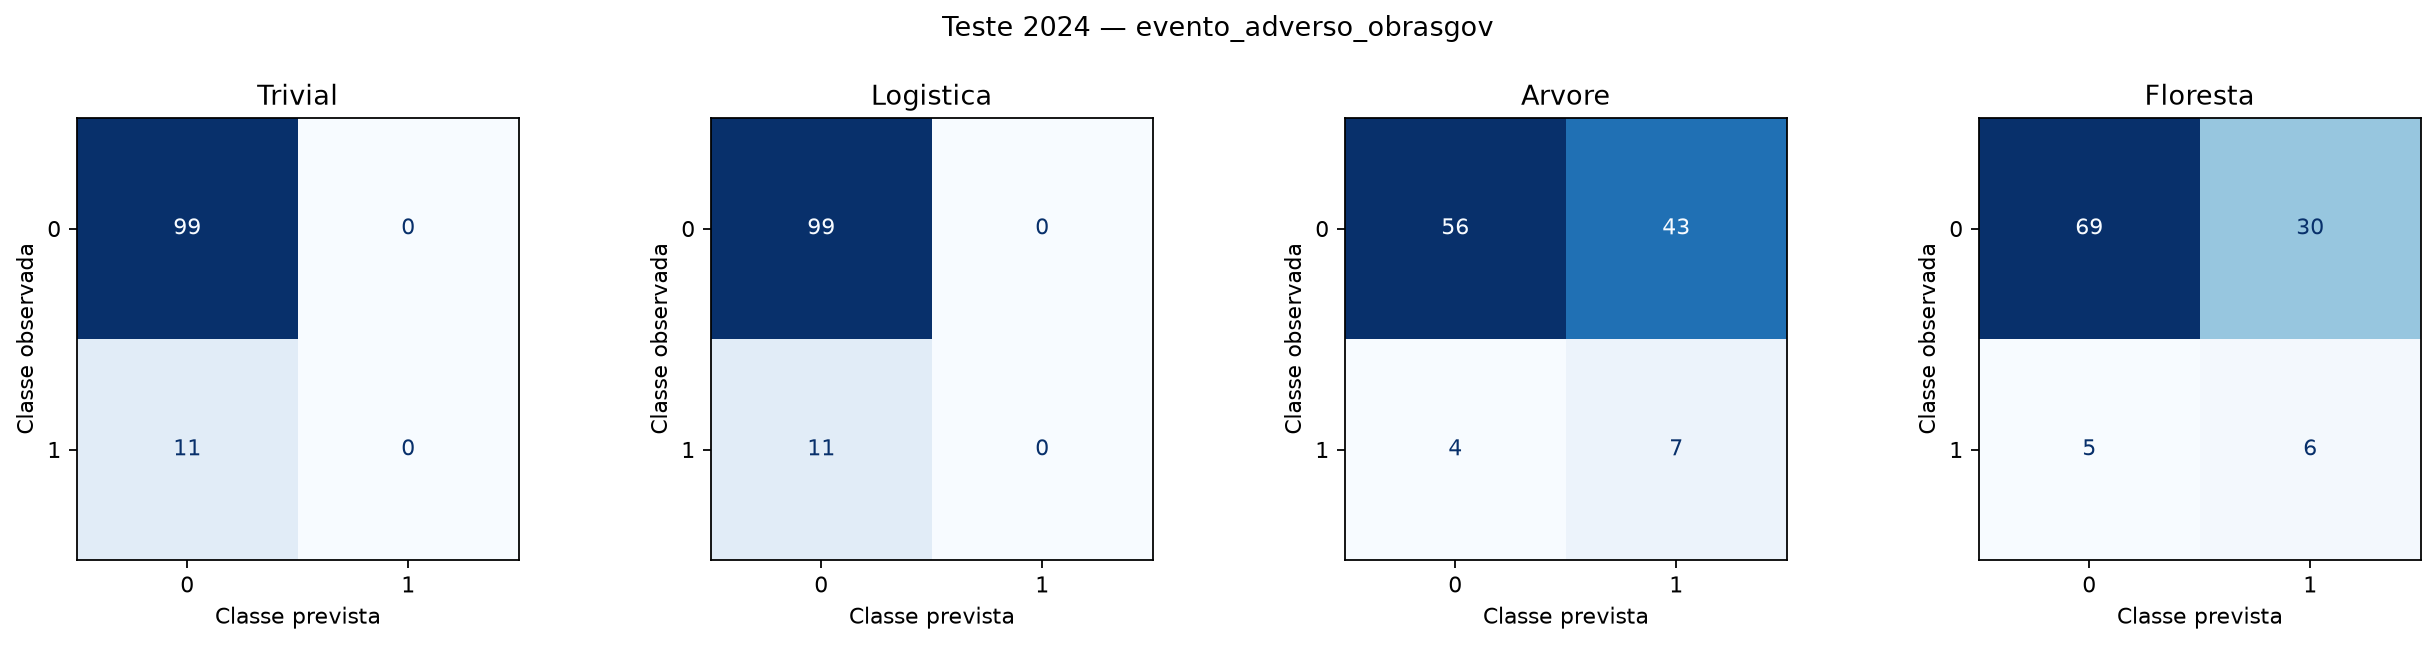

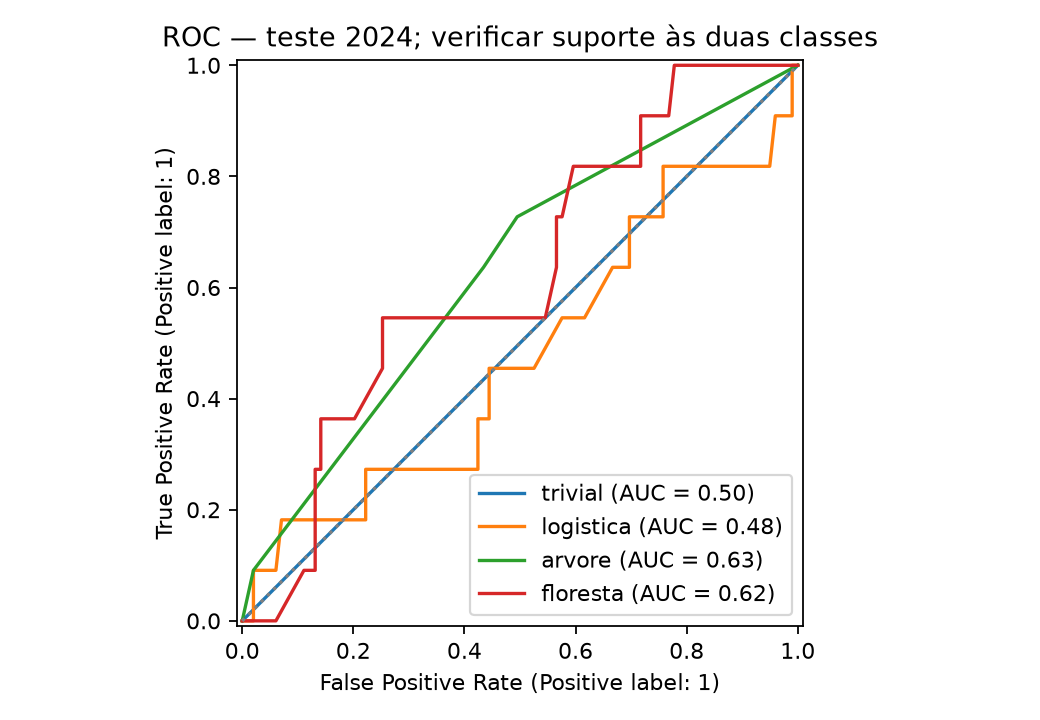

,modelo,metrica,inferior,superior,reamostragens_validas
0,arvore,acuracia_balanceada,0.432422,0.755833,1000
1,arvore,roc_auc,0.457669,0.790819,1000
2,arvore,average_precision,0.062407,0.334806,1000
3,floresta,acuracia_balanceada,0.467028,0.771909,1000
4,floresta,roc_auc,0.451441,0.774979,1000
5,floresta,average_precision,0.078753,0.297259,1000
6,logistica,acuracia_balanceada,0.500000,0.500000,1000
7,logistica,roc_auc,0.283401,0.677191,1000
8,logistica,average_precision,0.056180,0.337321,1000
9,trivial,acuracia_balanceada,0.500000,0.500000,1000


In [5]:
campos = ['nome', 'n', 'classe_1', 'acuracia_balanceada', 'roc_auc', 'average_precision',
          'mae_probabilidade', 'rmse_probabilidade', 'brier']
display(metricas[(metricas.analise == 'principal') & (metricas.particao == 'teste_2024')][campos])
referencia = ROOT / 'docs/e05/revisao_v2/metricas.csv'
if referencia.exists():
    pd.testing.assert_frame_equal(metricas.reset_index(drop=True), pd.read_csv(referencia), check_dtype=False, rtol=1e-12)
display(Image(filename=str(PASTA / 'notebook/principal/figuras/matrizes_confusao.png')))
display(Image(filename=str(PASTA / 'notebook/principal/figuras/roc_teste.png')))
display(pd.read_csv(PASTA / 'notebook/principal/intervalos_cluster.csv'))

## 6. Inspeção dos erros e do sobreajuste

Resíduos de classificação podem ser examinados como `y−p`, mas a análise deve destacar falsos negativos e falsos positivos. Não se exige normalidade desses resíduos para validar árvores. Comparar desempenho interno, validação e teste; um resultado pontual de 2024 não corrige uma validação fraca.

Os intervalos são condicionais ao teste e aos modelos ajustados, por reamostragem dos municípios; não simulam outros anos nem incluem toda a incerteza de seleção do modelo. A amostra tem poucos eventos e a exclusão de obras censuradas pode gerar viés de seleção.

In [6]:
p = pd.read_csv(PASTA / 'notebook/principal/predicoes_teste_2024.csv')
ids = p.groupby('modelo').id_projeto_investimento.apply(set)
assert all(i == ids.iloc[0] for i in ids)
p['residuo_probabilidade'] = p.y_real - p.probabilidade
p['erro'] = np.select([(p.y_real == 1) & (p.y_previsto == 0), (p.y_real == 0) & (p.y_previsto == 1)],
                     ['falso_negativo', 'falso_positivo'], default='acerto')
display(p.groupby(['modelo', 'erro']).size().unstack(fill_value=0))
display(p[p.modelo == 'arvore'].assign(erro_absoluto=lambda q: q.residuo_probabilidade.abs())
        .sort_values('erro_absoluto', ascending=False).head(10))

erro,acerto,falso_negativo,falso_positivo
modelo,,,
arvore,63,4,43
floresta,75,5,30
logistica,99,11,0
trivial,99,11,0


,id_projeto_investimento,codigo_ibge,data_corte,y_real,modelo,probabilidade,y_previsto,residuo_probabilidade,erro,erro_absoluto
292,34644.25-94,2503753,2024-01-01,1.0,arvore,0.000000,0,1.000000,falso_negativo,1.000000
296,34247.25-60,2514503,2024-01-01,1.0,arvore,0.000000,0,1.000000,falso_negativo,1.000000
294,34087.25-73,2511301,2024-01-01,1.0,arvore,0.000000,0,1.000000,falso_negativo,1.000000
282,48427.25-09,2516201,2024-01-01,0.0,arvore,0.731013,1,-0.731013,falso_positivo,0.731013
291,34562.25-38,2510808,2024-01-01,0.0,arvore,0.731013,1,-0.731013,falso_positivo,0.731013
220,33151.25-42,2512200,2024-01-01,0.0,arvore,0.671651,1,-0.671651,falso_positivo,0.671651
253,36580.25-18,2501401,2024-01-01,0.0,arvore,0.671651,1,-0.671651,falso_positivo,0.671651
243,34579.25-80,2510907,2024-01-01,0.0,arvore,0.671651,1,-0.671651,falso_positivo,0.671651
241,34620.25-44,2500775,2024-01-01,0.0,arvore,0.671651,1,-0.671651,falso_positivo,0.671651
223,48412.25-60,2502805,2024-01-01,0.0,arvore,0.671651,1,-0.671651,falso_positivo,0.671651


## 7. Sensibilidade separada — repasse em 180 dias

Alterar 90 para 180 dias não é a mesma tarefa que prever evento adverso em obra. Não escolhemos o horizonte que dá o melhor teste. A janela de 180 foi solicitada e fica explícita como outra análise.

No recorte estrito, desenvolvimento e validação continuam com classe única. O ajuste final possui apenas dois instrumentos com repasse em 180 dias e o teste tem três. Logo, uma ROC-AUC alta pode ser extremamente instável; não implica utilidade, e **não se compara sua AUC diretamente com a do alvo ObrasGov**. Sem validação discriminativa, não há candidato validado nessa análise.

In [7]:
display(pd.DataFrame(resultados['secundario']['classes_por_particao']).T)
display(metricas[(metricas.analise == 'secundario') & (metricas.particao == 'teste_2024')][campos])
print('Estado:', resultados['secundario']['status_conclusao'])
assert resultados['secundario']['candidato_validado'] is None
assert resultados['secundario']['intervalos']['status'].startswith('nao_estimado')

,n,classe_0,classe_1
treino_2022_validacao,46,0,46
validacao_2023,10,0,10
treino_final_2022_2023,249,2,247
teste_2024,242,3,239


,nome,n,classe_1,acuracia_balanceada,roc_auc,average_precision,mae_probabilidade,rmse_probabilidade,brier
9,Baseline trivial (prevalência do treino),242,239,0.5,0.500000,0.987603,0.020230,0.110734,0.012262
10,Baseline operacional (Regressão Logística),242,239,0.5,0.884240,0.998445,0.013480,0.111104,0.012344
12,Decision Tree Classifier,242,239,0.5,0.493724,0.987450,0.013855,0.112108,0.012568
14,Random Forest Classifier,242,239,0.5,0.853556,0.997805,0.017422,0.110359,0.012179


Estado: sem_validacao_discriminativa_classe_unica_2023


## 8. Conclusão e o que estes modelos não fazem

Concluímos um benchmarking reproduzível com um alvo observado mais próximo de risco de execução. Comparar os resultados não significa demonstrar causalidade, validar um índice multidimensional ou comprovar utilidade operacional. Os oito preditores são contexto municipal, sem atributos intrínsecos suficientes para explicar todos os problemas de uma obra.

Se um baseline superar as árvores na validação, isso deve orientar a conclusão, mesmo que uma árvore mostre uma métrica maior no teste já conhecido. A incerteza precisa acompanhar os números; não declarar um vencedor definitivo com cinco eventos na validação e 11 no teste.

O índice do artigo tem outro procedimento: selecionar âncoras e variáveis e compor dimensões com pesos. Importância de variável de uma árvore não substitui automaticamente esse procedimento nem vira peso causal de risco. Aprender a reproduzir uma pontuação calculada a partir das mesmas entradas seria circular como validação de risco.

**Para a defesa:** saber explicar y, a unidade, a censura, as datas de divulgação, o corte da coorte, CV por município, pesos balanceados, diferenças entre discriminação/calibração e a razão de preservar os baselines.

**IA e transparência:** Codex apoiou código, auditoria, testes e esta revisão técnica. Os dados são públicos e os resultados vêm das células executadas. Não foram refeitas Prospecção, Escuta ou Canvas já existentes. A equipe deve revisar e defender cada bloco.

**Referências:** artigo fornecido *Desafios e Oportunidades para o Desenvolvimento Regional*, pp. 5–6 e 12–15; apresentação própria *Predição de Fatores de Risco na Execução de Obras Públicas*, pp. 2–10; relatório E04 atualizado. Documentação técnica: [métricas](https://scikit-learn.org/stable/modules/model_evaluation.html), [árvores](https://scikit-learn.org/stable/modules/tree.html) e [CV por grupos](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).